In [ ]:
#Meshal Mahnoor

**Question # 01**
> 1. Choose an image containing circular objects (coins, bottle caps, plates, wheels, etc.).
> 2. Detect circles using cv2.HoughCircles() and draw each one with its center marked and radius labeled
using cv2.putText().
3. Display the total count of detected circles on the image.
Tune the parameters until detection is accurate, and report the final values you used.

In [ ]:
#imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

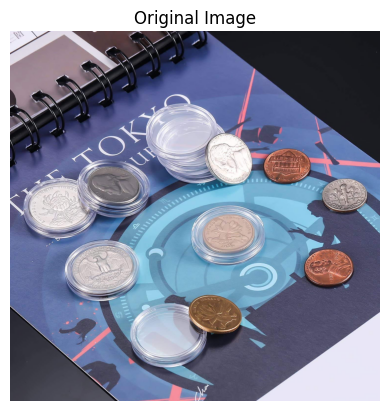

In [ ]:
#original image:
image_path = "coins.jpg"
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')
plt.show()

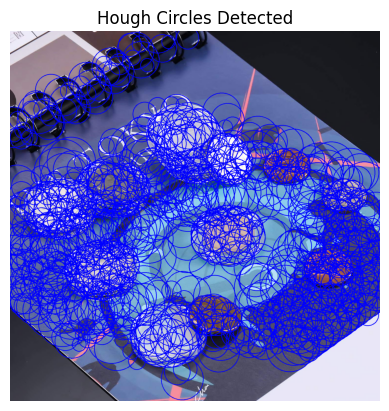

In [ ]:
#Hough Circle Transform using HoughCircles
img_circles = img.copy()
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30, param1=100, param2=30, minRadius=20, maxRadius=100)
if circles is not None:
  circles = np.uint16(np.around(circles))
  for x, y, r in circles[0, :]:
    cv2.circle(img_circles, (x, y), r, (255, 0, 0), 2)
plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
plt.title("Hough Circles Detected")
plt.axis('off')
plt.show()

/tmp/ipykernel_1316/3145931926.py:14: RuntimeWarning: overflow encountered in scalar subtract
  cv2.putText(img_circles, text, (x - 40, y - 10),


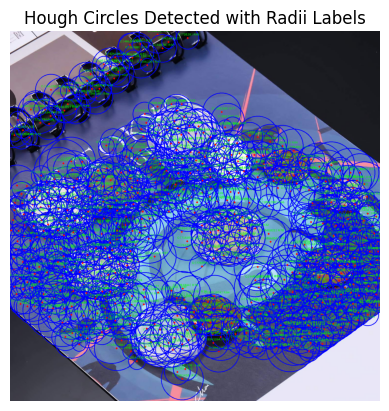

In [ ]:
#using cv2 putText to marks the radii
img_circles = img.copy()
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30,param1=100, param2=30, minRadius=20, maxRadius=100)

if circles is not None:
    circles = np.uint16(np.around(circles))
    for x, y, r in circles[0, :]:
      #outer circle:
        cv2.circle(img_circles, (x, y), r, (255, 0, 0), 2)
        #Dot in the middle of circle
        cv2.circle(img_circles, (x, y), 2, (0, 0, 255), 3)
        #Label format
        text = f"C:({x},{y}) R:{r}"
        cv2.putText(img_circles, text, (x - 40, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)
plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
plt.title("Hough Circles Detected with Radii Labels")
plt.axis('off')
plt.show()


Total circles detected: 771


/tmp/ipykernel_1316/1983732664.py:16: RuntimeWarning: overflow encountered in scalar subtract
  cv2.putText(img_circles, text, (x - 40, y - 10),


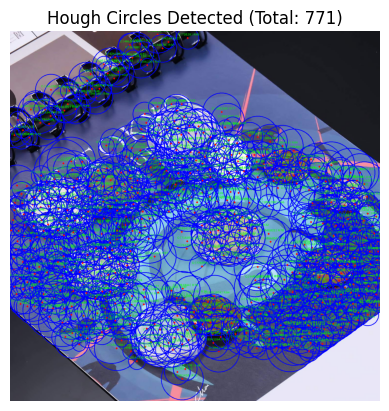

In [ ]:
#Counting the total circles in this image:
img_circles = img.copy()
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30,param1=100, param2=30, minRadius=20, maxRadius=100)
# Initialize counter
total_circles = 0

if circles is not None:
    circles = np.uint16(np.around(circles))
    #Count the total number of circles
    total_circles = len(circles[0, :])
    print(f"Total circles detected: {total_circles}")
    for x, y, r in circles[0, :]:
        cv2.circle(img_circles, (x, y), r, (255, 0, 0), 2)
        cv2.circle(img_circles, (x, y), 2, (0, 0, 255), 3)
        text = f"C:({x},{y}) R:{r}"
        cv2.putText(img_circles, text, (x - 40, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)
else:
    print("No circles found in this detection.")

plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
plt.title(f"Hough Circles Detected (Total: {total_circles})") #plot the count
plt.axis('off')
plt.show()


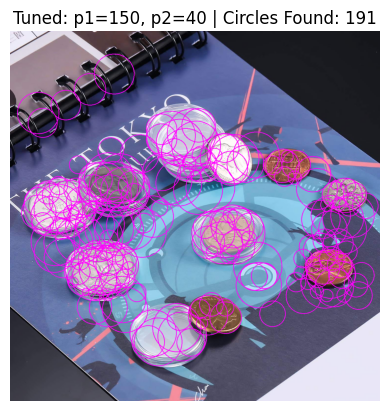

In [ ]:
#we need to fine tune these results, check the value each time and fine tune again if need be:
tuned_circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=0.8, minDist=40,
param1=150, param2=40, minRadius=10, maxRadius=100)
output_tuned = img.copy()
total_circles = tuned_circles.shape[1] if tuned_circles is not None else 0
if tuned_circles is not None:
 tuned_circles = np.uint16(np.around(tuned_circles))
 for x, y, r in tuned_circles[0, :]:
  cv2.circle(output_tuned, (x, y), r, (255, 0, 255), 2)
plt.imshow(cv2.cvtColor(output_tuned, cv2.COLOR_BGR2RGB))
plt.title("Effect of Parameter Tuning (Stronger Edges)")
plt.title(f"Tuned: p1=150, p2=40 | Circles Found: {total_circles}")
plt.axis('off')
plt.show()

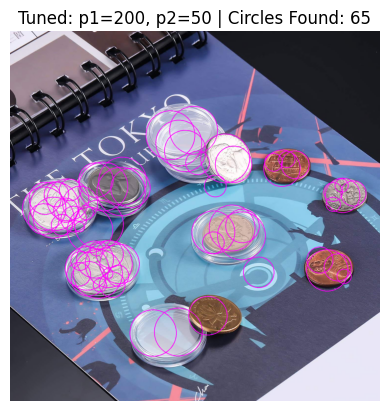

In [ ]:
#fine tuning again:
tuned_circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=0.8, minDist=40,
param1=200, param2=50, minRadius=10, maxRadius=100)
output_tuned = img.copy()

# Count the total circles
total_circles = tuned_circles.shape[1] if tuned_circles is not None else 0

if tuned_circles is not None:
    tuned_circles = np.uint16(np.around(tuned_circles))
    for x, y, r in tuned_circles[0, :]:
        cv2.circle(output_tuned, (x, y), r, (255, 0, 255), 2)

plt.imshow(cv2.cvtColor(output_tuned, cv2.COLOR_BGR2RGB))
plt.title(f"Tuned: p1=200, p2=50 | Circles Found: {total_circles}")
plt.axis("off")
plt.show()


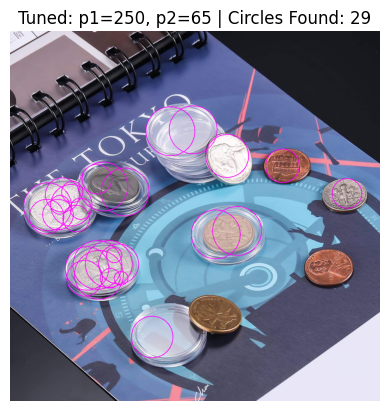

In [ ]:
#one last fine tuning to get near accurate results:
#fine tuning again:
tuned_circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=0.8, minDist=40,
param1=250, param2=65, minRadius=10, maxRadius=100)
output_tuned = img.copy()

# Count the total circles
total_circles = tuned_circles.shape[1] if tuned_circles is not None else 0

if tuned_circles is not None:
    tuned_circles = np.uint16(np.around(tuned_circles))
    for x, y, r in tuned_circles[0, :]:
        cv2.circle(output_tuned, (x, y), r, (255, 0, 255), 2)

plt.imshow(cv2.cvtColor(output_tuned, cv2.COLOR_BGR2RGB))
plt.title(f"Tuned: p1=250, p2=65 | Circles Found: {total_circles}")
plt.axis("off")
plt.show()


**Observations:**
The original image has give or take 12 circles in it, the original image is read using cv2.
Using the Hough Transform voting technique the machine votes on detecting 711 circles.
Then each circles radii and center is marked using putText().
>
***Fine Tuning:***
>The 711 circles are not at all an accurate depiction of the original image, so to overcome this, we must fine tune using our parameters(param1, param2) to get accurate results.
>
In the first fine tune we take values of 150 and 40, which gives us 191 voted circles, which is drastically better than 711.
>
The 'model' needs further tuning, so we increase the values to 200 and 50 giving us voted 65 circles.
>
The last fine tuning detects 29 circles, with values of 250 and 65.
>
>*param1* represents Edge sensitivity: Higher means stricter Canny edge threshold.
>
>*param2* represents Circle certainty: HIGHER reduces fake circles; LOWER detects faint ones
>
`NOTE: The model was detecting bunched circles in the image when the fine tuning reached level 3, more or less, so that is closest to an accurate depiction.`

**Question # 02**
For road lanes detection, apply both cv2.HoughLines() and cv2.HoughLinesP().
> 1. Draw standard Hough lines in red and probabilistic lines in green on separate copies of the image.
> 2. Print the total number of lines detected by each method.
> 3. Explain which one is better for finding actual object boundaries and why.

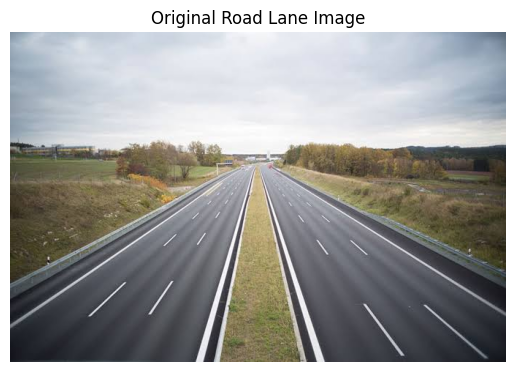

In [ ]:
#Standard Hough Lines:
#image for this:
image_path = "roads.jpg"
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Road Lane Image")
plt.axis('off')
plt.show()

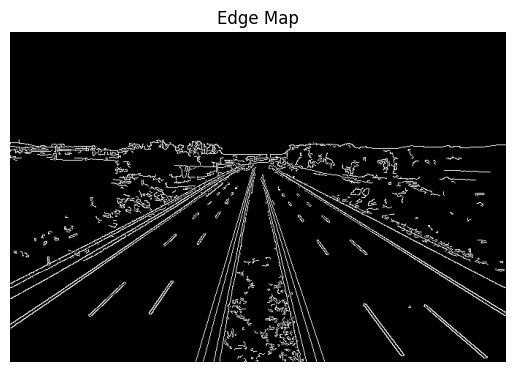

In [ ]:
#detecting canny lines first before standard transform:
edges = cv2.Canny(gray, 100, 200)
plt.imshow(edges, cmap='gray')
plt.title("Edge Map")
plt.axis('off')
plt.show()

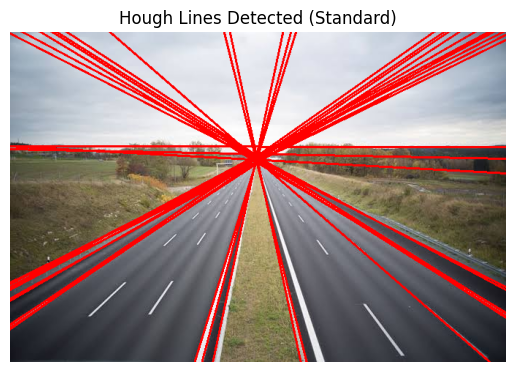

In [ ]:
img_lines = img.copy()
lines = cv2.HoughLines(edges, 1, np.pi/180, 150)
if lines is not None:
 for rho, theta in lines[:, 0]:
  a, b = np.cos(theta), np.sin(theta)
  x0, y0 = a*rho, b*rho
  x1, y1 = int(x0 + 1000*(-b)), int(y0 + 1000*(a))

  x2, y2 = int(x0 - 1000*(-b)), int(y0 - 1000*(a))
  cv2.line(img_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)
plt.imshow(cv2.cvtColor(img_lines, cv2.COLOR_BGR2RGB))
plt.title("Hough Lines Detected (Standard)")
plt.axis('off')
plt.show()

In [ ]:
#lines detected by this method:
num_lines = len(lines) if lines is not None else 0
print(num_lines)

26


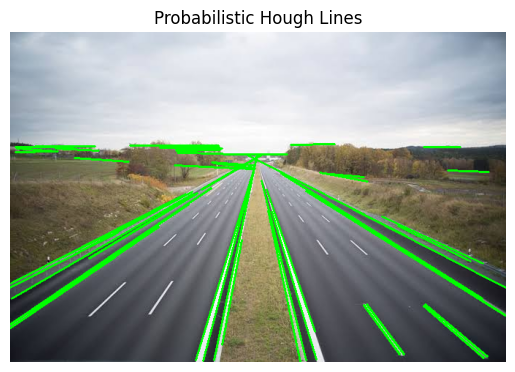

In [ ]:
#Hough Lines Probabilistic:
img_prob = img.copy()
lines_p = cv2.HoughLinesP(
edges,
1,
np.pi / 180,
threshold=100,
minLineLength=50,
maxLineGap=10
)
if lines_p is not None:
 lines_p = lines_p.reshape(-1, 4)
 for x1, y1, x2, y2 in lines_p:
  cv2.line(
img_prob,
(x1, y1),
(x2, y2),
(0, 255, 0),
2
)
plt.imshow(cv2.cvtColor(img_prob, cv2.COLOR_BGR2RGB))

plt.title("Probabilistic Hough Lines")
plt.axis('off')
plt.show()

In [ ]:
#lines detected by this method:
num_lines = len(lines_p) if lines is not None else 0
print(num_lines)

49


**Observations:**
Original Image of two lanes loaded using cv2.
>
Using canny to detect image edges.
>
Using standard Hough Lines to detect straight lines in an image.
>
Using Hough Line P to detect staright line in an image.
>
>HoughLinesP (Probabilistic Hough Transform) is generally better and faster for most practical line detection tasks than the standard HoughLines function, in this case because it identifies exact start/end coordinates of line segments.